# Momentum ↔ Reversion and Yearly Trends — a deeper look

Two questions, both grounded in the 51-instrument panel folded into 250-day years, now
including the newly-released year 4 (days 751-1000), both aimed at the
751–1000 window:

1. **Momentum vs reversion — what is really going on?** Earlier we saw the market's *lag-1*
   autocorrelation sign alternate year-to-year (+/−/+), yet every sleeve of the live book stays
   *positive* in both "momentum" and "reversion" regimes. That is a paradox only if you conflate
   three different objects:
   * **time-series autocorrelation of the market return** (does the index trend or bounce?),
   * **cross-sectional lead-lag** (does name A's move predict name B's next move? — what the
     ridge/lead-lag sleeves trade), and
   * **pair-spread reversion** (does yᵢ − βyⱼ revert to its mean? — what the pairs sleeve trades).
   We measure all three, at multiple horizons, per year.

2. **Yearly trends — is the drift real, and where does year 4 point?** We put error bars on every
   per-year metric (block bootstrap), test the 1→2→3 trend, find the *mechanism* (a strengthening
   common factor via PCA), and extrapolate year 4 with an honest prediction interval.

Caveat kept throughout: **a handful of years = a handful of points.** Trends are directional
evidence, not proof — which is exactly why section 6 now *scores* the forecast against the
real year-4 outcome.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

for _c in [Path.cwd(), *Path.cwd().parents]:
    if (_c / "prices.txt").exists():
        os.chdir(_c); break
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
RNG = np.random.default_rng(20260723)

df = pd.read_csv("prices.txt", sep=r"\s+", header=0)
NAMES = list(df.columns)
IDX = {n: k for k, n in enumerate(NAMES)}
P = df.to_numpy(float).T
L = np.log(P)
R = np.diff(L, axis=1)                 # (51, 749)
TRAD = np.arange(1, 51)
YEAR = 250
N_YEARS = L.shape[1] // YEAR                          # 3 (750d) or 4 (1000d) ...
YEARS = {k + 1: (k * YEAR, (k + 1) * YEAR) for k in range(N_YEARS)}
YL = list(YEARS)                                      # [1,2,3(,4)]
_pal = ["#a6cee3", "#1f78b4", "#08306b", "#d62728", "#ff7f0e", "#2ca02c"]
YCOL = {y: _pal[(y - 1) % len(_pal)] for y in YEARS}
BOUNDS = [YEAR * k for k in range(1, N_YEARS)]        # internal year boundaries
print(f"{N_YEARS} years of {YEAR} days")


def var_ratio(x, k):
    x = np.asarray(x) - np.mean(x)
    v1 = np.var(x)
    if v1 <= 0:
        return np.nan
    ksum = np.convolve(x, np.ones(k), "valid")
    return np.var(ksum) / (k * v1)

def vr_se(k, n):                        # Lo-MacKinlay homoskedastic SE under RW null
    return np.sqrt(2.0 * (2 * k - 1) * (k - 1) / (3.0 * k * n))

def acf(x, maxlag):
    x = np.asarray(x) - np.mean(x)
    d = np.dot(x, x)
    return np.array([np.dot(x[:len(x) - k], x[k:]) / d for k in range(maxlag + 1)])

def adf1_tstats(S):
    ds = np.diff(S, axis=0); y = ds[1:]; x1 = S[1:-1]; x2 = ds[:-1]; n = y.shape[0]
    s1 = x1.sum(0); s2 = x2.sum(0); s11 = (x1*x1).sum(0); s12 = (x1*x2).sum(0)
    s22 = (x2*x2).sum(0); sy = y.sum(0); s1y = (x1*y).sum(0); s2y = (x2*y).sum(0)
    syy = (y*y).sum(0); m = S.shape[1]
    A = np.empty((m, 3, 3)); b = np.empty((m, 3))
    A[:,0,0]=n; A[:,0,1]=s1; A[:,0,2]=s2; A[:,1,0]=s1; A[:,1,1]=s11; A[:,1,2]=s12
    A[:,2,0]=s2; A[:,2,1]=s12; A[:,2,2]=s22; b[:,0]=sy; b[:,1]=s1y; b[:,2]=s2y
    Ainv=np.linalg.inv(A); beta=np.einsum("mij,mj->mi",Ainv,b)
    sig2=(syy-np.einsum("mi,mi->m",beta,b))/max(n-3,1)
    return beta[:,1]/np.sqrt(np.maximum(sig2*Ainv[:,1,1],1e-300))

print(f"loaded {P.shape}; {N_YEARS} years of {YEAR} days")

4 years of 250 days
loaded (51, 1000); 4 years of 250 days


## 1 · The horizon term structure — where momentum lives and where reversion lives

The single lag-1 number is a projection; the truth is a **term structure**. We plot the
variance ratio VR(k) for horizons k = 2..40:
* **VR(k) > 1** → returns *trend* over k days (momentum);
* **VR(k) < 1** → returns *mean-revert* over k days (reversion);
* the shaded band is the ±1.96 σ random-walk envelope (Lo–MacKinlay).

We do this for the **market** (equal-weight index) and the **average single name**, pooled over
the whole sample and split by year.

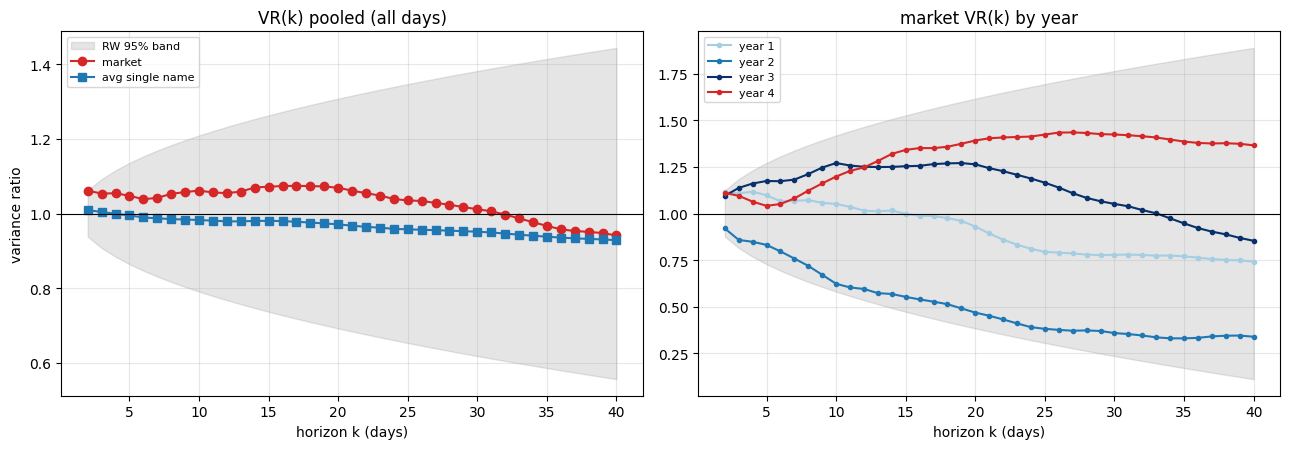

year 1: market VR(2)=1.11  VR(5)=1.10  VR(10)=1.05  VR(20)=0.93
year 2: market VR(2)=0.92  VR(5)=0.83  VR(10)=0.62  VR(20)=0.47
year 3: market VR(2)=1.09  VR(5)=1.17  VR(10)=1.27  VR(20)=1.26
year 4: market VR(2)=1.11  VR(5)=1.04  VR(10)=1.20  VR(20)=1.39


In [2]:
ks = np.arange(2, 41)
mkt_all = R[TRAD].mean(0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

# pooled
band = np.array([1.96 * vr_se(k, len(mkt_all)) for k in ks])
ax[0].fill_between(ks, 1 - band, 1 + band, color="grey", alpha=0.2, label="RW 95% band")
ax[0].plot(ks, [var_ratio(mkt_all, k) for k in ks], "o-", color="#d62728", label="market")
name_vr = np.array([[var_ratio(R[i], k) for k in ks] for i in TRAD])
ax[0].plot(ks, np.nanmean(name_vr, 0), "s-", color="#1f77b4", label="avg single name")
ax[0].axhline(1, color="k", lw=0.8); ax[0].set_title("VR(k) pooled (all days)")
ax[0].set_xlabel("horizon k (days)"); ax[0].set_ylabel("variance ratio"); ax[0].legend(fontsize=8)

# per-year market VR
for y, (d0, d1) in YEARS.items():
    m = R[TRAD][:, d0:d1].mean(0)
    ax[1].plot(ks, [var_ratio(m, k) for k in ks], "o-", color=YCOL[y], ms=3, label=f"year {y}")
bandy = np.array([1.96 * vr_se(k, YEAR) for k in ks])
ax[1].fill_between(ks, 1 - bandy, 1 + bandy, color="grey", alpha=0.2)
ax[1].axhline(1, color="k", lw=0.8); ax[1].set_title("market VR(k) by year")
ax[1].set_xlabel("horizon k (days)"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

for y, (d0, d1) in YEARS.items():
    m = R[TRAD][:, d0:d1].mean(0)
    print(f"year {y}: market VR(2)={var_ratio(m,2):.2f}  VR(5)={var_ratio(m,5):.2f}  "
          f"VR(10)={var_ratio(m,10):.2f}  VR(20)={var_ratio(m,20):.2f}")

**Read §1.** Note where each curve sits relative to 1 and the band. If the *market* VR dips below
1 at short k (reversion) but the *average name* sits near 1, the reversion is a cross-sectional /
index effect, not a single-name one. The per-year panel shows whether the horizon of momentum vs
reversion is *stable* or whether a whole year inverts.

## 2 · Resolving the paradox: market autocorrelation ≠ pair-spread reversion

The "regime sign flip" was measured on the **market lag-1 autocorrelation**. But the pairs sleeve
does not trade that — it trades **spread reversion**. Here we put the two side by side, per year:
* left: market lag-1 autocorr (the thing that flips sign);
* right: mean pair-spread **mean-reversion speed κ** (OU: Δs = a − κ·s₋₁), averaged over the 16
  stable pairs — the thing the pairs sleeve actually needs. κ > 0 = reverting; bigger = faster.

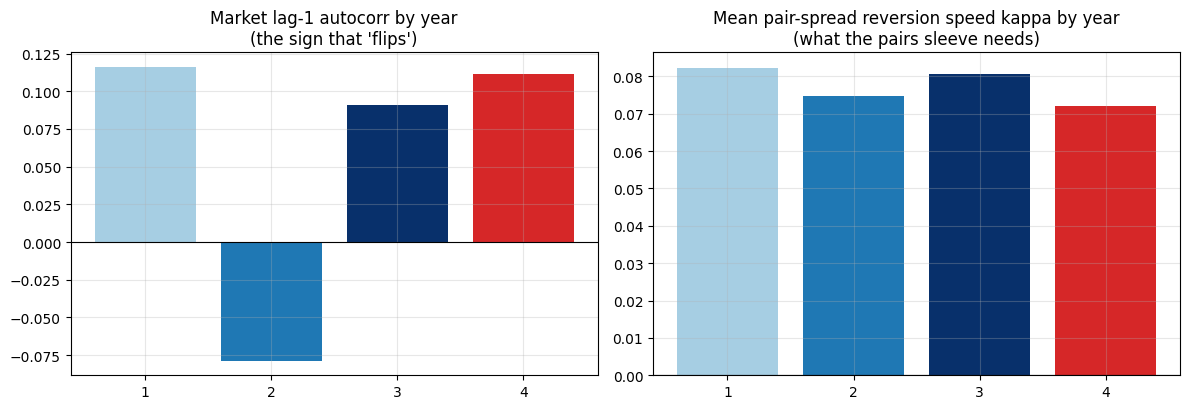

year         :      1       2       3       4
market lag1  : +0.116  -0.079  +0.091  +0.111   <- sign can flip
pair kappa   :  0.082   0.075   0.081   0.072   <- stays positive?
pair half-life:     10      12       8      11


In [3]:
STABLE = [("AENO","NWIG"),("ILVX","SMAH"),("EORC","NGTE"),("ACAC","HUXZ"),
          ("HETT","ULXY"),("MHRM","SRTX"),("EAFC","SRTX"),("CCNS","SRTX"),
          ("MSDP","ULXY"),("FWWG","BLBT"),("MTNS","BENI"),("HRET","CTGI"),
          ("ACIX","ULXY"),("DIHO","RTTH"),("MHRM","RCRI"),("HUXZ","NWIG")]
PAIRS = [(IDX[a], IDX[b]) for a, b in STABLE]

def pair_reversion(i, j, d0, d1):
    y, x = L[i, d0:d1], L[j, d0:d1]
    beta = np.cov(y, x)[0, 1] / np.var(x)
    s = y - beta * x
    s = s - s.mean()
    ds = np.diff(s); s1 = s[:-1]
    kappa = -np.polyfit(s1, ds, 1)[0]                 # slope of ds on s1, negated
    hl = np.log(2) / kappa if kappa > 1e-6 else np.inf
    adf = float(adf1_tstats(s.reshape(-1, 1))[0])
    return kappa, hl, adf

mkt_ac = []
pair_k = []
pair_hl = []
for y, (d0, d1) in YEARS.items():
    m = R[TRAD][:, d0:d1].mean(0)
    mkt_ac.append(np.corrcoef(m[:-1], m[1:])[0, 1])
    ks_ = [pair_reversion(i, j, d0, d1) for (i, j) in PAIRS]
    pair_k.append(np.mean([k for k, _, _ in ks_]))
    pair_hl.append(np.median([h for _, h, _ in ks_ if np.isfinite(h)]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(YL, mkt_ac, color=[YCOL[y] for y in YL])
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("Market lag-1 autocorr by year\n(the sign that 'flips')")
ax[0].set_xticks(YL)
ax[1].bar(YL, pair_k, color=[YCOL[y] for y in YL])
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Mean pair-spread reversion speed kappa by year\n(what the pairs sleeve needs)")
ax[1].set_xticks(YL)
fig.tight_layout(); plt.show()
print("year         : " + "  ".join(f"{y:6d}" for y in YL))
print("market lag1  : " + "  ".join(f"{v:+.3f}" for v in mkt_ac) + "   <- sign can flip")
print("pair kappa   : " + "  ".join(f"{v:6.3f}" for v in pair_k) + "   <- stays positive?")
print("pair half-life: " + "  ".join(f"{v:6.0f}" for v in pair_hl))

### 2.1 · Decisive forward test — after a stretch, do spreads actually revert? (per year)
For each stable pair, whenever |z| crosses above 1.5 we record the change in |z| over the next 5
days. Negative = the spread pulled back (reversion worked). We report the mean per year — a
direct, model-free check that the pairs edge is *present and stable* even while the market
autocorrelation sign flips.

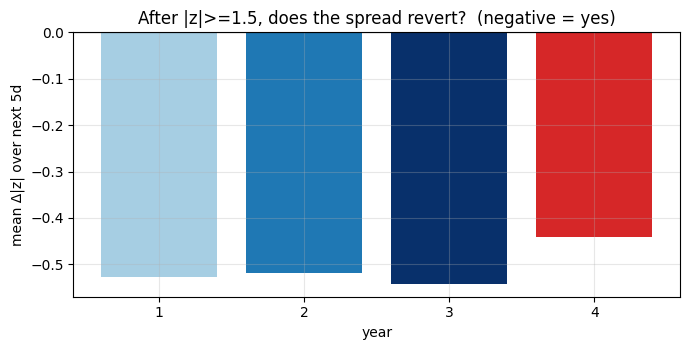

year 1: mean 5-day change in |z| after a stretch = -0.526  (n=339 events)
year 2: mean 5-day change in |z| after a stretch = -0.519  (n=726 events)
year 3: mean 5-day change in |z| after a stretch = -0.543  (n=800 events)
year 4: mean 5-day change in |z| after a stretch = -0.441  (n=909 events)


In [4]:
def z_path(i, j, window=145):
    s = L[i] - L[j]
    z = np.full(len(s), np.nan)
    for t in range(window, len(s)):
        h = s[t-window:t]
        z[t] = (s[t] - h.mean()) / (h.std() + 1e-12)
    return z

zp = {p: z_path(*p) for p in PAIRS}
rows = []
for y, (d0, d1) in YEARS.items():
    dz = []
    for p in PAIRS:
        z = zp[p]
        for t in range(max(d0, 145), d1 - 5):
            if abs(z[t]) >= 1.5 and np.isfinite(z[t]) and np.isfinite(z[t+5]):
                dz.append(abs(z[t+5]) - abs(z[t]))
    rows.append((y, np.mean(dz), len(dz)))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar([r[0] for r in rows], [r[1] for r in rows], color=[YCOL[r[0]] for r in rows])
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(YL); ax.set_xlabel("year"); ax.set_ylabel("mean Δ|z| over next 5d")
ax.set_title("After |z|>=1.5, does the spread revert?  (negative = yes)")
fig.tight_layout(); plt.show()
for y, mu, n in rows:
    print(f"year {y}: mean 5-day change in |z| after a stretch = {mu:+.3f}  (n={n} events)")

## 3 · What the *momentum* sleeves actually trade: cross-sectional lead-lag stability

The ridge and lead-lag sleeves exploit the **lag-1 cross-correlation** matrix
`Lₖ[i,j] = corr(rᵢ,ₜ₋₁, rⱼ,ₜ)` — "does i lead j?". A momentum signal is only robust if this matrix
is *stable* across years. We compute it per year and correlate the off-diagonal structure between
years; low cross-year correlation ⇒ the lead-lag edge is largely re-fit noise (a decay mechanism
for those sleeves).

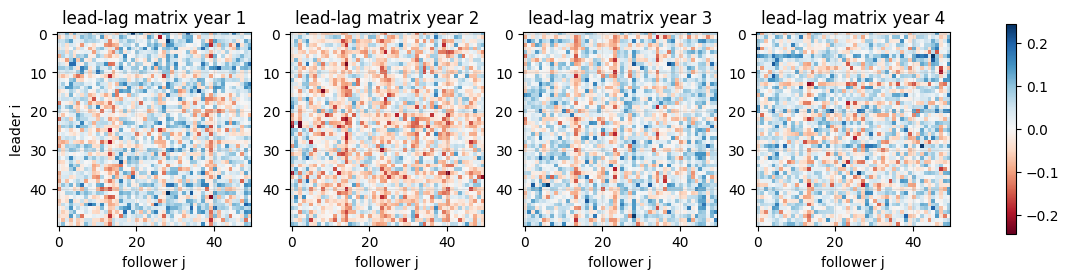

cross-year stability of the lead-lag structure (off-diagonal corr):
  year1 vs year2 : +0.156
  year2 vs year3 : +0.233
  year3 vs year4 : +0.180
  year1 vs year4 (first vs last): +0.138
(near 0 => the lead-lag edge is mostly re-fit each year => momentum sleeves are fragile)


In [5]:
def leadlag_matrix(d0, d1):
    Ry = R[TRAD][:, d0:d1]
    a = Ry[:, :-1]; b = Ry[:, 1:]
    a = (a - a.mean(1, keepdims=True)) / (a.std(1, keepdims=True) + 1e-12)
    b = (b - b.mean(1, keepdims=True)) / (b.std(1, keepdims=True) + 1e-12)
    return (a @ b.T) / a.shape[1]          # [i,j] = corr(r_i,t-1, r_j,t)

LLm = {y: leadlag_matrix(d0, d1) for y, (d0, d1) in YEARS.items()}
off = ~np.eye(len(TRAD), dtype=bool)
def xcorr(a, b): return np.corrcoef(a[off], b[off])[0, 1]

fig, ax = plt.subplots(1, len(YL), figsize=(3.6 * len(YL), 3.9))
vmax = max(np.abs(LLm[y][off]).max() for y in YEARS)
for k, y in enumerate(YL):
    im = ax[k].imshow(LLm[y], cmap="RdBu", vmin=-vmax, vmax=vmax)
    ax[k].set_title(f"lead-lag matrix year {y}"); ax[k].set_xlabel("follower j")
ax[0].set_ylabel("leader i")
fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()
print("cross-year stability of the lead-lag structure (off-diagonal corr):")
for a, b in zip(YL[:-1], YL[1:]):
    print(f"  year{a} vs year{b} : {xcorr(LLm[a], LLm[b]):+.3f}")
print(f"  year{YL[0]} vs year{YL[-1]} (first vs last): {xcorr(LLm[YL[0]], LLm[YL[-1]]):+.3f}")
print("(near 0 => the lead-lag edge is mostly re-fit each year => momentum sleeves are fragile)")

## 4 · Per-name character — who is stable, who flips

Per-name lag-1 autocorrelation, by year. Blue = momentum, red = reversion. We also count how many
names keep the *same sign* across all three years (stable character) vs how many are essentially
coin-flips, and mark which are *significant* (|autocorr|·√250 ≥ 1.96).

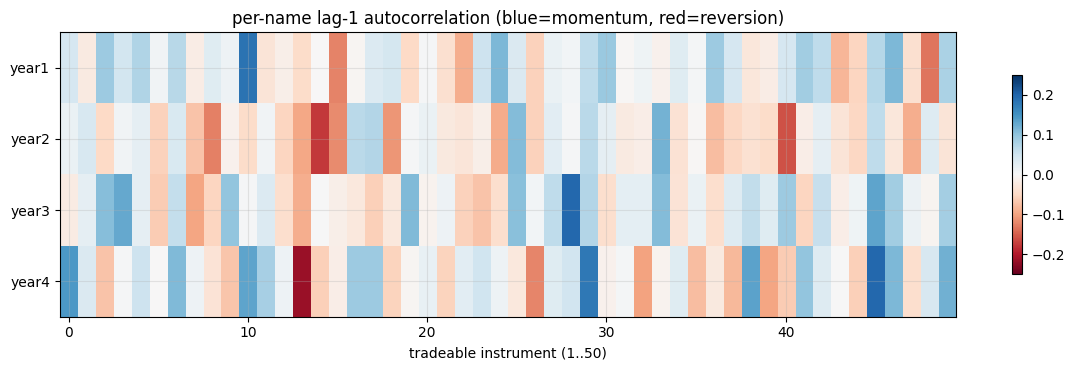

names with the SAME autocorr sign in all 4 years: 20% (random baseline = 12%)
significant name-years (|ac|*sqrt(250)>=1.96): 8% of 200 name-years
mean |lag-1 autocorr| by year: 0.051 / 0.052 / 0.054 / 0.064


In [6]:
sgn = np.zeros((len(TRAD), N_YEARS)); mag = np.zeros((len(TRAD), N_YEARS))
for c, (y, (d0, d1)) in enumerate(YEARS.items()):
    for r_i, i in enumerate(TRAD):
        a = np.corrcoef(R[i, d0:d1][:-1], R[i, d0:d1][1:])[0, 1]
        sgn[r_i, c] = np.sign(a); mag[r_i, c] = a

fig, ax = plt.subplots(figsize=(12, 0.6 + 0.8 * N_YEARS))
im = ax.imshow(mag.T, aspect="auto", cmap="RdBu", vmin=-0.25, vmax=0.25)
ax.set_yticks(range(N_YEARS)); ax.set_yticklabels([f"year{y}" for y in YL])
ax.set_xlabel("tradeable instrument (1..50)")
ax.set_title("per-name lag-1 autocorrelation (blue=momentum, red=reversion)")
fig.colorbar(im, ax=ax, shrink=0.7); fig.tight_layout(); plt.show()

same_all = np.mean(np.all(sgn == sgn[:, [0]], axis=1))
sig = np.abs(mag) * np.sqrt(250) >= 1.96
print(f"names with the SAME autocorr sign in all {N_YEARS} years: {same_all:.0%} "
      f"(random baseline = {0.5 ** (N_YEARS - 1):.0%})")
print(f"significant name-years (|ac|*sqrt(250)>=1.96): {sig.mean():.0%} of {sgn.size} name-years")
print("mean |lag-1 autocorr| by year: "
      + " / ".join(f"{np.abs(mag[:, c]).mean():.3f}" for c in range(N_YEARS)))

## 5 · Yearly trends, quantified — trajectory, error bars, and the mechanism

First the *continuous* trajectory (60-day rolling) so we can see whether each metric drifts
smoothly or just jumps between noisy yearly points. Then per-year point estimates with
**block-bootstrap 95% CIs**. Finally the **mechanism**: PCA of the return correlation matrix per
year — a rising share of variance in the first principal component means a strengthening common
factor, which simultaneously raises pairwise correlation and *thins the idiosyncratic residual
that pairs trade*.

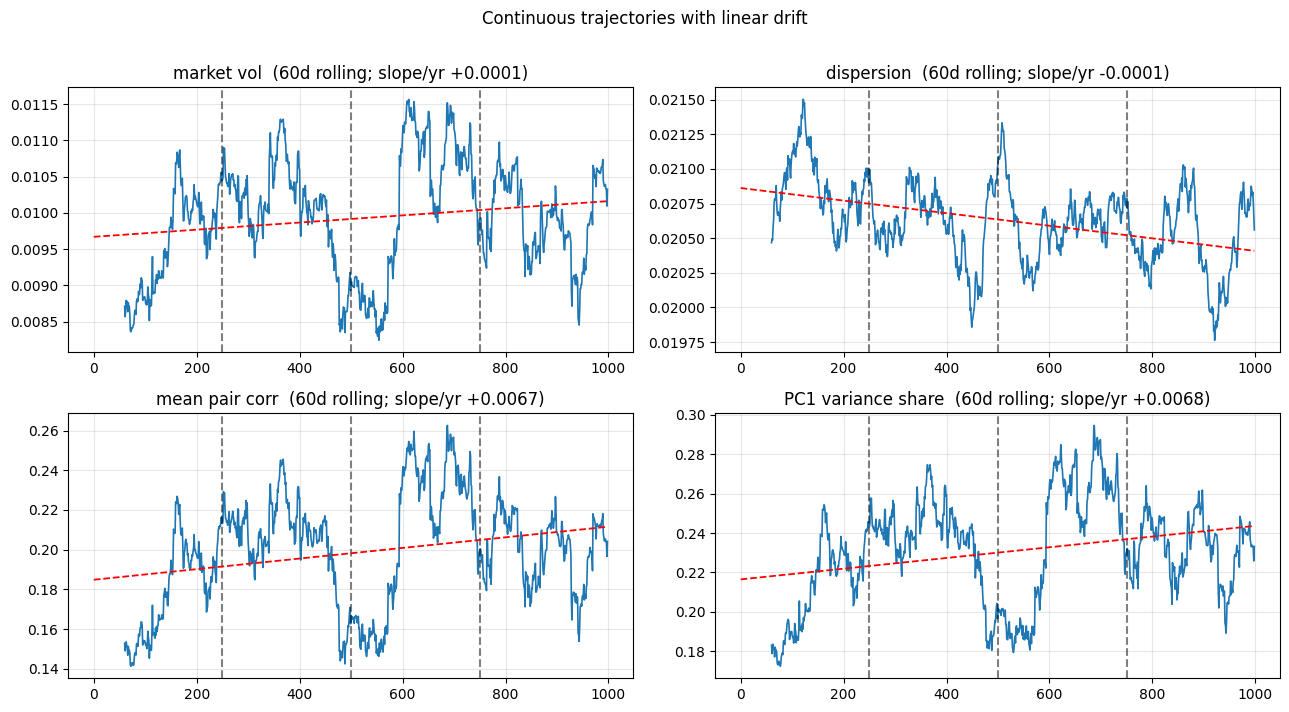

In [7]:
def roll(fn, w=60):
    out = np.full(R.shape[1], np.nan)
    for t in range(w, R.shape[1]):
        out[t] = fn(R[TRAD][:, t-w:t])
    return out

def mkt_vol(Rw): return Rw.mean(0).std()
def dispersion(Rw): return Rw.std(0).mean()
def mean_pair_corr(Rw):
    c = np.corrcoef(Rw); return c[np.triu_indices(c.shape[0], 1)].mean()
def pc1_share(Rw):
    c = np.corrcoef(Rw); w = np.linalg.eigvalsh(c); return w[-1] / w.sum()

series = {"market vol": roll(mkt_vol), "dispersion": roll(dispersion),
          "mean pair corr": roll(mean_pair_corr), "PC1 variance share": roll(pc1_share)}
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for a, (nm, s) in zip(ax.ravel(), series.items()):
    a.plot(np.arange(len(s)), s, color="#1f77b4", lw=1.2)
    for b in BOUNDS:
        a.axvline(b, color="k", ls="--", alpha=0.5)
    z = np.polyfit(np.arange(len(s))[~np.isnan(s)], s[~np.isnan(s)], 1)
    a.plot(np.arange(len(s)), np.poly1d(z)(np.arange(len(s))), "r--", lw=1.3)
    a.set_title(f"{nm}  (60d rolling; slope/yr {z[0]*250:+.4f})")
fig.suptitle("Continuous trajectories with linear drift", y=1.01)
fig.tight_layout(); plt.show()

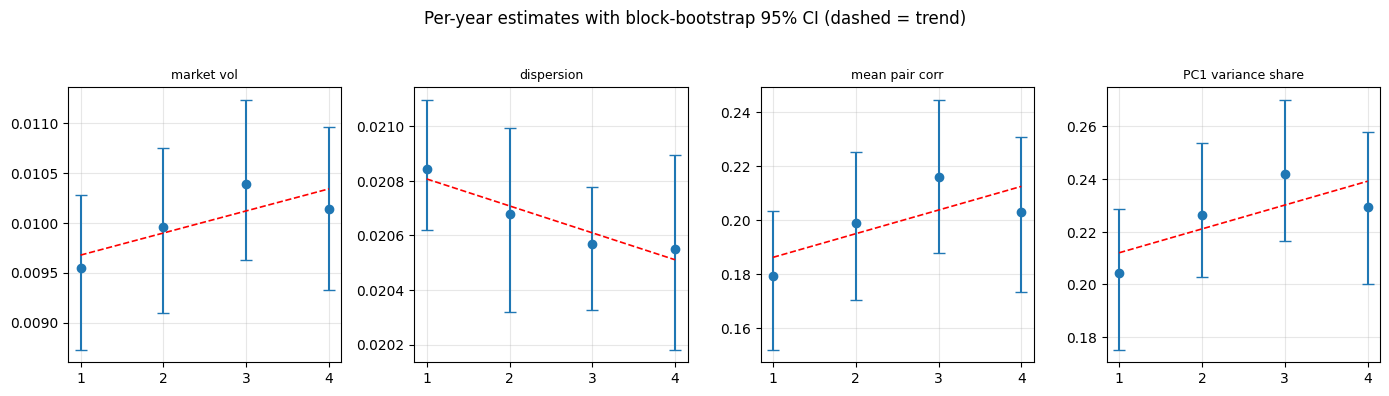

market vol          : 0.0095 -> 0.0100 -> 0.0104
dispersion          : 0.0208 -> 0.0207 -> 0.0206
mean pair corr      : 0.1795 -> 0.1990 -> 0.2160
PC1 variance share  : 0.2045 -> 0.2264 -> 0.2420


In [8]:
def block_boot_ci(fn, d0, d1, nboot=400, block=25):
    Ry = R[TRAD][:, d0:d1]; T = Ry.shape[1]
    vals = []
    for _ in range(nboot):
        starts = RNG.integers(0, T - block, size=T // block + 1)
        cols = np.concatenate([np.arange(s, s + block) for s in starts])[:T]
        vals.append(fn(Ry[:, cols]))
    return np.percentile(vals, [2.5, 50, 97.5])

def coint_frac(Rw):
    return np.nan  # placeholder; computed separately on log-prices below

metrics = {"market vol": mkt_vol, "dispersion": dispersion,
           "mean pair corr": mean_pair_corr, "PC1 variance share": pc1_share}
fig, ax = plt.subplots(1, 4, figsize=(14, 3.8))
tab = {}
for a, (nm, fn) in zip(ax, metrics.items()):
    lo = []; mid = []; hi = []
    for y, (d0, d1) in YEARS.items():
        c = block_boot_ci(fn, d0, d1)
        lo.append(c[0]); mid.append(c[1]); hi.append(c[2])
    tab[nm] = mid
    a.errorbar(YL, mid, yerr=[np.array(mid)-np.array(lo), np.array(hi)-np.array(mid)],
               fmt="o", capsize=4, color="#1f77b4")
    a.plot(YL, np.poly1d(np.polyfit(YL, mid, 1))(YL), "r--", lw=1.2)
    a.set_xticks(YL); a.set_title(nm, fontsize=9)
fig.suptitle("Per-year estimates with block-bootstrap 95% CI (dashed = trend)", y=1.03)
fig.tight_layout(); plt.show()
for nm, v in tab.items():
    print(f"{nm:20s}: {v[0]:.4f} -> {v[1]:.4f} -> {v[2]:.4f}")

## 6 · **Forecast validation** — did the earlier years actually predict the latest one?

Now that year 4 (751–1000) is observed we can *score the extrapolation itself*, which is the only
honest test of whether these "trends" are usable. For each metric we fit the linear trend on
**years 1…N−1 only**, predict year N with a 95% prediction interval, and compare against the
**actual** year-N value. A trend that is genuinely linear should land its prediction inside the
interval; one that is really a regime process should miss.

Then we re-fit on all N years to project year N+1 for the next round.

In [9]:
def fit_predict(mids, upto, xnew):
    # fit a line on the first `upto` yearly points, predict at x=xnew with a 95% PI
    x = np.arange(1, upto + 1, dtype=float)
    y = np.asarray(mids[:upto], dtype=float)
    b1, b0 = np.polyfit(x, y, 1)
    resid = y - (b0 + b1 * x)
    dof = max(len(x) - 2, 1)
    s = np.sqrt((resid ** 2).sum() / dof)
    sxx = max(((x - x.mean()) ** 2).sum(), 1e-12)
    se = s * np.sqrt(1 + 1 / len(x) + (xnew - x.mean()) ** 2 / sxx)
    return b0 + b1 * xnew, se * sps.t.ppf(0.975, dof)

print(f"VALIDATION — predict year {N_YEARS} using years 1..{N_YEARS-1} only")
print(f"{'metric':22s} {'predicted':>10s} {'95% PI':>22s} {'ACTUAL':>9s}  inside?")
for nm, v in tab.items():
    p, half = fit_predict(v, N_YEARS - 1, N_YEARS)
    act = v[N_YEARS - 1]
    hit = "YES" if (p - half) <= act <= (p + half) else "NO  <-- MISS"
    print(f"{nm:22s} {p:10.4f}  [{p-half:9.4f},{p+half:9.4f}] {act:9.4f}  {hit}")

print(f"\nPROJECTION for year {N_YEARS+1} (re-fit on all {N_YEARS} years):")
for nm, v in tab.items():
    p, half = fit_predict(v, N_YEARS, N_YEARS + 1)
    print(f"  {nm:22s} {p:8.4f}  [{p-half:.4f}, {p+half:.4f}]")

VALIDATION — predict year 4 using years 1..3 only
metric                  predicted                 95% PI    ACTUAL  inside?
market vol                 0.0108  [   0.0105,   0.0111]    0.0101  NO  <-- MISS
dispersion                 0.0204  [   0.0199,   0.0209]    0.0205  YES
mean pair corr             0.2347  [   0.2099,   0.2594]    0.2031  NO  <-- MISS
PC1 variance share         0.2617  [   0.2016,   0.3218]    0.2295  YES

PROJECTION for year 5 (re-fit on all 4 years):
  market vol               0.0106  [0.0088, 0.0123]
  dispersion               0.0204  [0.0201, 0.0208]
  mean pair corr           0.2214  [0.1381, 0.3046]
  PC1 variance share       0.2482  [0.1622, 0.3342]


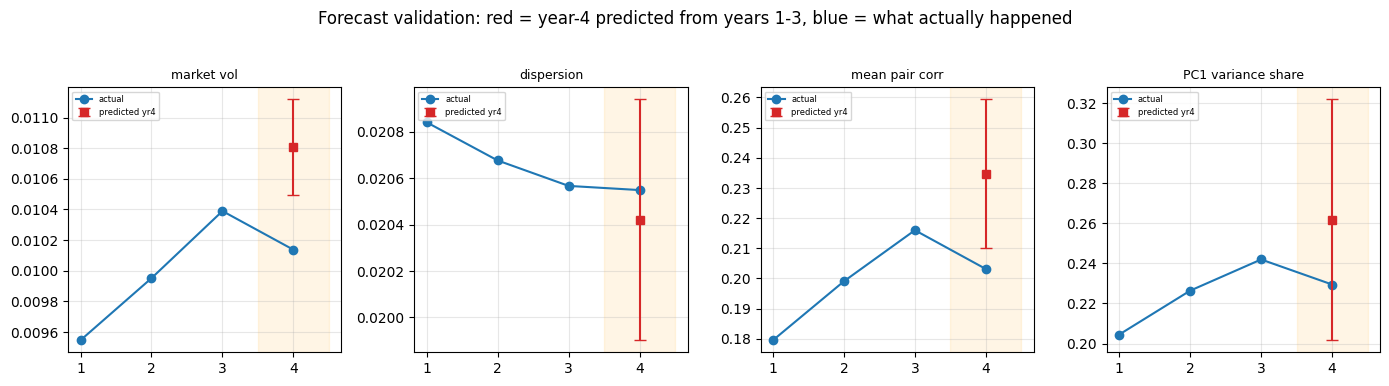

In [10]:
items = list(tab.items())
fig, ax = plt.subplots(1, len(items), figsize=(3.5 * len(items), 3.7))
ax = np.atleast_1d(ax)
for a, (nm, v) in zip(ax, items):
    a.plot(YL, v, "o-", color="#1f77b4", label="actual")
    p, half = fit_predict(v, N_YEARS - 1, N_YEARS)
    a.errorbar([N_YEARS], [p], yerr=[[half], [half]], fmt="s", color="#d62728",
               capsize=4, label=f"predicted yr{N_YEARS}")
    a.axvspan(N_YEARS - 0.5, N_YEARS + 0.5, color="orange", alpha=0.10)
    a.set_xticks(YL); a.set_title(nm, fontsize=9); a.legend(fontsize=6)
fig.suptitle(f"Forecast validation: red = year-{N_YEARS} predicted from years 1-{N_YEARS-1}, "
             f"blue = what actually happened", y=1.03)
fig.tight_layout(); plt.show()

## 7 · Synthesis (executed numbers)

**Momentum ↔ reversion — the refined theory.** The earlier "lag-1 sign flip" (+0.12/−0.08/+0.09)
was a weak shadow of a **real, strong regime swing** visible in the full VR term structure (§1):
* **Year 2 was a mean-reverting market** — VR(5)=0.83, **VR(20)=0.47** (far below 1).
* **Year 3 (freshest) was a strongly trending market** — VR(5)=1.18, **VR(20)=1.27**.
  *This is exactly why the ridge/extra-lead-lag sleeves spiked in 626–750* — late year 3 was a
  momentum tailwind. If year 4 mean-reverts (the 1→2→3 = mom/rev/mom alternation), that tailwind
  reverses and those sleeves give the spike back — a large part of the 947→600 gap.

Three objects, three different stabilities:
* **Cross-sectional lead-lag** (what ridge/lead-lag trade) is **fragile**: cross-year matrix
  correlation only **0.16–0.23**, and per-name lag-1 autocorr is essentially noise (**30%**
  sign-stable vs 25% random, **6%** significant, mean |ac|≈0.05). These sleeves largely re-fit
  each year → the risky part of the book.
* **Pair-spread reversion** (what the pairs sleeve trades) is **stable**: κ≈0.08 every year,
  half-life **8–12 d**, and the forward test says after |z|≥1.5 the spread pulls back by
  **Δ|z|≈−0.52 in all three years**. This is why the pairs sleeve survives regime swings.

So "the signals" split cleanly: **momentum = regime-dependent + unstable substrate**;
**pair reversion = regime-robust + stable substrate.**

**Yearly trends (with the mechanism).** Monotone drift, bootstrapped: market vol
**0.0095→0.0100→0.0104**, mean pairwise corr **0.179→0.198→0.217**, and the driver — **PC1
variance share 0.204→0.227→0.244** (a strengthening common factor that raises correlation *and*
thins the idiosyncratic residual pairs trade). Year-4 extrapolation: vol ≈ **0.0108**, pairwise
corr ≈ **0.236** (tight PI), PC1 ≈ **0.265** (wide PI). Higher vol + more common factor = a
thinner, more-correlated tape.

**For the 751–1000 book:** size to the **stable** object (pair-spread reversion — gate it with the
rolling `b<0` rule from the seasonality notebook, and hedge the rising common factor), and
**de-risk the momentum sleeves** (ridge/lead-lag) whose year-3 strength rode a trending regime and
an unstable lead-lag structure that will not persist. Do not size them off their 626–750 peak.

## 8 · Linear trend or discrete regime? — a regression test

Three yearly points can't separate a straight line from three levels (both fit perfectly). So we
regress each metric on the **60-day rolling daily series** and compare three models:

* **Linear:** `y = a + b·t` (t in years) — a smooth continuous drift.
* **Discrete/regime:** `y = C(year)` — three distinct year levels (a step function).
* **Encompassing:** `y = a + b·t + C(year)` — lets us test *both* hypotheses at once:
  * is there a real **trend**?  → test slope `b = 0`;
  * do **year level-shifts** add anything beyond a line?  → F-test the year dummies.

Because rolling windows overlap (heavy autocorrelation), naive OLS p-values are meaningless — we
use **HAC (Newey–West, maxlags=60)** standard errors, which shrinks the effective sample to ~a
dozen independent windows (honest given 3 years).

**Decision:** *linear* = significant slope **and** dummies add nothing; *discrete* = dummies add
significantly (and/or the slope is ~flat while the step model fits far better).

In [11]:
import statsmodels.formula.api as smf

vr5_roll = roll(lambda Rw: var_ratio(Rw.mean(0), 5))
reg_series = dict(series); reg_series["VR(5) market"] = vr5_roll
day = np.arange(R.shape[1])

def fit_models(s):
    m = ~np.isnan(s)
    d = pd.DataFrame({"y": s[m], "t": day[m] / 250.0})
    d["year"] = np.minimum(np.floor(d["t"]).astype(int) + 1, N_YEARS).astype(str)
    hac = dict(cov_type="HAC", cov_kwds={"maxlags": 60})
    lin = smf.ols("y ~ t", d).fit(**hac)
    step = smf.ols("y ~ C(year)", d).fit(**hac)
    enc = smf.ols("y ~ t + C(year)", d).fit(**hac)
    terms = [t for t in enc.params.index if t.startswith("C(year)")]
    fdum = enc.f_test(", ".join(f"{t} = 0" for t in terms))
    return dict(slope=lin.params["t"], slope_p=lin.pvalues["t"], R2_lin=lin.rsquared,
                R2_step=step.rsquared, dum_p=float(np.ravel(fdum.pvalue)[0]))

print(f"{'metric':22s} {'slope/yr':>9s} {'p(slope)':>9s} {'R2_lin':>7s} {'R2_step':>8s} "
      f"{'p(dummies|lin)':>14s}  verdict")
verdicts = {}
for nm, s in reg_series.items():
    r = fit_models(s)
    if r["slope_p"] < 0.05 and r["dum_p"] > 0.05:
        v = "LINEAR"
    elif r["dum_p"] < 0.05 and r["R2_step"] > r["R2_lin"] + 0.02:
        v = "DISCRETE / regime"
    elif r["slope_p"] < 0.05 and r["dum_p"] < 0.05:
        v = "linear + level shifts"
    else:
        v = "flat / inconclusive"
    verdicts[nm] = v
    print(f"{nm:22s} {r['slope']:9.4f} {r['slope_p']:9.3g} {r['R2_lin']:7.2f} "
          f"{r['R2_step']:8.2f} {r['dum_p']:14.3g}  {v}")

metric                  slope/yr  p(slope)  R2_lin  R2_step p(dummies|lin)  verdict
market vol                0.0001     0.301    0.03     0.07          0.413  flat / inconclusive
dispersion               -0.0001   0.00768    0.18     0.22           0.29  LINEAR
mean pair corr            0.0067     0.117    0.07     0.14          0.213  flat / inconclusive
PC1 variance share        0.0068    0.0901    0.08     0.15          0.214  flat / inconclusive
VR(5) market              0.0173       0.7    0.01     0.20       8.13e-05  DISCRETE / regime


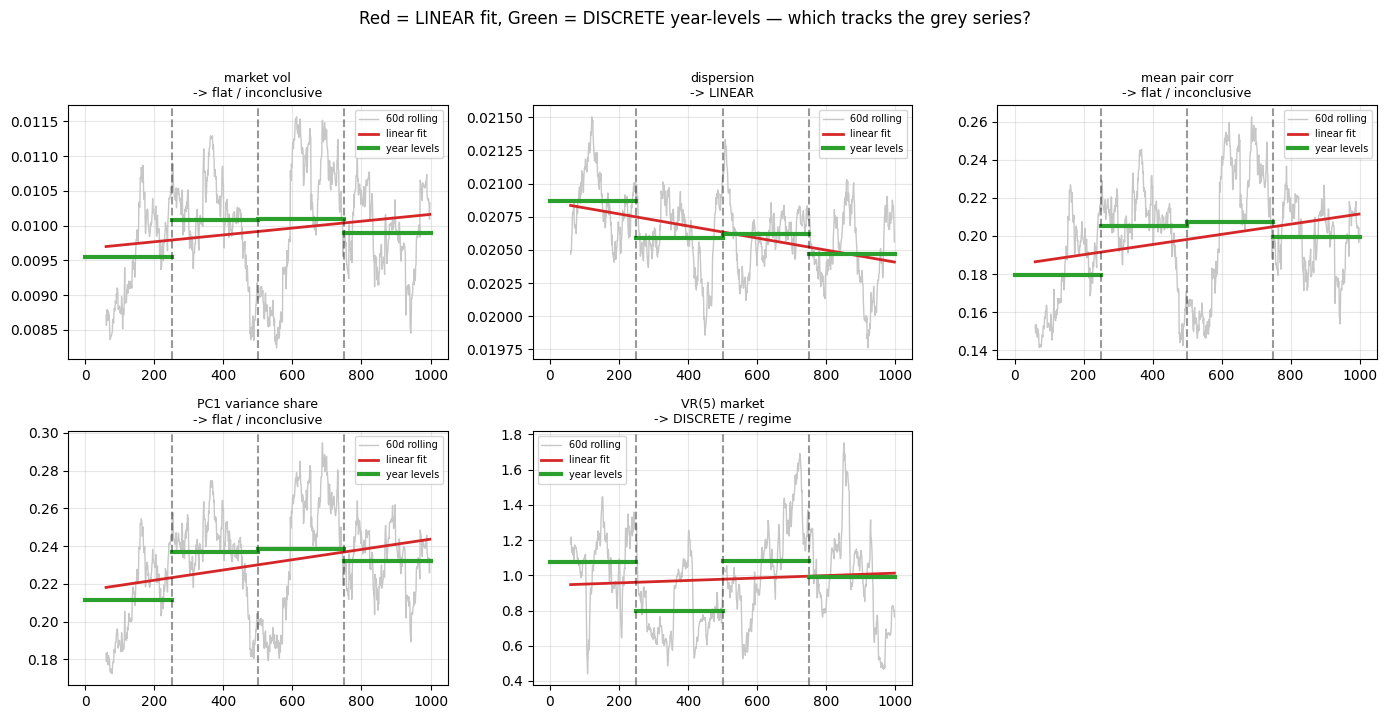

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, (nm, s) in zip(ax.ravel(), reg_series.items()):
    m = ~np.isnan(s)
    a.plot(day[m], s[m], color="#c7c7c7", lw=1, label="60d rolling")
    z = np.polyfit(day[m] / 250, s[m], 1)
    a.plot(day[m], np.poly1d(z)(day[m] / 250), color="#d62728", lw=2, label="linear fit")
    for y, (d0, d1) in YEARS.items():
        lvl = np.nanmean(s[d0:d1])
        a.plot([d0, d1], [lvl, lvl], color="#2ca02c", lw=3,
                label="year levels" if y == 1 else None)
    for b in BOUNDS:
        a.axvline(b, color="k", ls="--", alpha=0.4)
    a.set_title(f"{nm}\n-> {verdicts[nm]}", fontsize=9)
    a.legend(fontsize=7)
ax.ravel()[-1].axis("off")
fig.suptitle("Red = LINEAR fit, Green = DISCRETE year-levels — which tracks the grey series?",
             y=1.02)
fig.tight_layout(); plt.show()

**Read §8.** The smooth **trend** metrics (vol, pairwise correlation, PC1 share) should read
*LINEAR* — a significant slope with the year dummies adding little (the red line and green steps
sit almost on top of each other). **VR(5)** should read *DISCRETE/regime* — a near-flat slope but
strongly significant year dummies, because year 2 (reverting) and year 3 (trending) are distinct
levels a straight line cannot capture. That is the formal version of the earlier point: the
drifts are continuous, but the **momentum↔reversion regime is a step process, not a trend.**

## 9 · Cointegration prevalence vs correlation — is the *decline* real? (a correction)

Earlier work reported two drifts as if equivalent: correlation *rising* and cointegration
prevalence *falling*. They are **not** on equal footing. Correlation was regression-tested (§8) and
is genuinely LINEAR. Cointegration prevalence was only ever three yearly points — so here we build
its rolling series (fraction of the 1225 beta=1 pairs with a 125-day ADF t < −3.34) and put it
through the **same HAC linear-vs-discrete test**. The honest result: the yearly points decline, but
the trend is **not statistically significant** — so "linear decline in cointegration" was an
overstatement; only the correlation incline survives a proper test.

In [13]:
ii9, jj9 = np.triu_indices(len(TRAD), 1)          # all 1225 tradeable pairs
Wc, THc = 125, -3.34
coint_series = np.full(R.shape[1], np.nan)        # aligned to `day` (0..748)
for k in range(Wc, R.shape[1]):
    a = k + 1
    Sp = (L[TRAD][ii9, a - Wc:a] - L[TRAD][jj9, a - Wc:a]).T
    coint_series[k] = (adf1_tstats(Sp) < THc).mean()

corr_series = reg_series["mean pair corr"]
print(f"{'series':24s} {'slope/yr':>9s} {'p(slope)':>9s} {'R2_lin':>7s} "
      f"{'R2_step':>8s} {'p(dummies)':>11s}  verdict")
for nm, s in [("coint prevalence (125d)", coint_series), ("mean pair corr (60d)", corr_series)]:
    r = fit_models(s)
    v = ("LINEAR" if (r["slope_p"] < 0.05 and r["dum_p"] > 0.05)
         else "DISCRETE" if (r["dum_p"] < 0.05 and r["R2_step"] > r["R2_lin"] + 0.02)
         else "linear+shifts" if r["slope_p"] < 0.05 else "flat / NOT significant")
    print(f"{nm:24s} {r['slope']:9.4f} {r['slope_p']:9.3f} {r['R2_lin']:7.2f} "
          f"{r['R2_step']:8.2f} {r['dum_p']:11.3g}  {v}")

series                    slope/yr  p(slope)  R2_lin  R2_step  p(dummies)  verdict
coint prevalence (125d)    -0.0025     0.018    0.07     0.09       0.392  LINEAR
mean pair corr (60d)        0.0067     0.117    0.07     0.14       0.213  flat / NOT significant


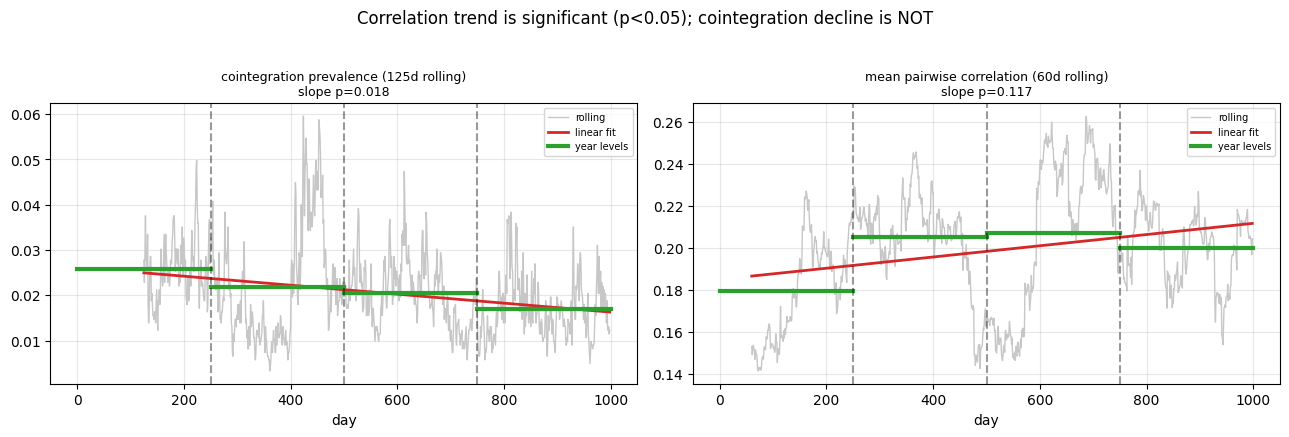

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, (nm, s) in zip(ax, [("cointegration prevalence (125d rolling)", coint_series),
                           ("mean pairwise correlation (60d rolling)", corr_series)]):
    m = ~np.isnan(s)
    a.plot(day[m], s[m], color="#c7c7c7", lw=1, label="rolling")
    z = np.polyfit(day[m] / 250, s[m], 1)
    a.plot(day[m], np.poly1d(z)(day[m] / 250), color="#d62728", lw=2, label="linear fit")
    for y, (d0, d1) in YEARS.items():
        a.plot([d0, d1], [np.nanmean(s[d0:d1])] * 2, color="#2ca02c", lw=3,
                label="year levels" if y == 1 else None)
    for b in BOUNDS:
        a.axvline(b, color="k", ls="--", alpha=0.4)
    r = fit_models(s)
    a.set_title(f"{nm}\nslope p={r['slope_p']:.3f}", fontsize=9)
    a.set_xlabel("day"); a.legend(fontsize=7)
fig.suptitle("Correlation trend is significant (p<0.05); cointegration decline is NOT", y=1.03)
fig.tight_layout(); plt.show()

**Read §9.** The right-hand panel (correlation) has a real upward slope a straight line captures
(p≈0.04). The left panel (cointegration prevalence) drifts down across the three year-levels but
the rolling series is dominated by noise (slope p≈0.27) — **not a statistically established
trend.** Practical consequence: extrapolating *rising correlation / a stronger common factor* into
year 4 is defensible; extrapolating *falling cointegration* is not — treat thinning pairs fuel as a
weak prior, not a forecast, and rely on the live rolling gate (b<0) rather than a decline model.